In [ ]:
import matplotlib.pyplot as plt
from matplotlib_inline.backend_inline import set_matplotlib_formats


# Plotting
set_matplotlib_formats("retina")

plt.style.use(
    "https://raw.githubusercontent.com/"
    "ksingh1121/python-plot-style/main/physics.mplstyle"
)


In [ ]:
import slmsuite

from slmsuite.hardware.cameraslms import FourierSLM

print("slmsuite version:", slmsuite.__version__)
print("Imports successful.")

slmsuite version: 0.4.1
Imports successful.


c:\Users\admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\slmsuite\holography\algorithms\_header.py:30: UserWarning: cupy is not installed; using numpy. Install cupy for faster GPU-based holography.
  warnings.warn(


In [ ]:
from pathlib import Path

from slmsuite.hardware.slms.meadowlark import Meadowlark

print("SLM imports successful.")

SLM imports successful.


In [ ]:
# Meadowlark paths

SDK_PATH = Path(
    r"C:\Program Files\Meadowlark Optics\Blink 1920 HDMI\SDK"
)

LUT_PATH = Path(
    r"C:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\Experiment scripts"
    r"\LUT_locked_759nm_20260811_201109\759nm_KS_global_20260811.lut"
)


print("SDK exists :", SDK_PATH.exists())
print("LUT exists :", LUT_PATH.exists())

# Initialize SLM

slm = Meadowlark(
    slm_number=1,
    sdk_path=str(SDK_PATH),
    lut_path=str(LUT_PATH),
    wav_um=0.7593,
    verbose=True,
)


print("\n=== SLM READY ===")
print("Name       :", slm.name)
print("Shape      :", slm.shape)
print("Wavelength :", slm.wav_um, "um")
print("Pixel pitch:", slm.pitch_um, "um")

SDK exists : True
LUT exists : True
Validating DPI awareness...success
Constructing Blink SDK...success
Loading LUT file...
=== SLM READY ===
Name       : Meadowlark HDMI
Shape      : (1200, 1920)
Wavelength : 0.7593 um
Pixel pitch: [8. 8.] um


In [ ]:
from slmsuite.hardware.cameras.alliedvision import AlliedVision

CAMERA_SERIAL = "015C2"

cam = AlliedVision(
    serial=CAMERA_SERIAL,
    verbose=True,
)


print("\n=== CAMERA READY ===")
print("Shape     :", cam.shape)
print("WOI       :", cam.woi)
print("Exposure  :", cam.exposure_s, "s")
print("Bit depth :", cam.bitdepth)

vmbpy initializing... success
Looking for cameras... success
vmbpy sn '015C2' initializing... success

=== CAMERA READY ===
Shape     : (3672, 5496)
WOI       : (0, 5496, 0, 3672)
Exposure  : 0.005997181 s
Bit depth : 8


c:\Users\admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\slmsuite\hardware\cameras\camera.py:444: UserWarning: '015C2' _get_image_hw() failed 5 times before quitting.
  warnings.warn(f"'{self.name}' _get_image_hw() failed {failures} times before quitting.")


## 16-pixel blaze

This is just for diagnostic purpose to have a known blaze and see where it falls on the camera

In [ ]:
import numpy as np

# SLM shape
H, W = slm.shape   # expected (1200, 1920)

# Blaze period in SLM pixels
period = 16

# x coordinate across the SLM
x = np.arange(W)

# Phase ramp from 0 to 2pi, repeating every 16 pixels
phase_1d = 2 * np.pi * (x % period) / period

# Repeat along y
phase = np.tile(phase_1d, (H, 1))

# Write to SLM
slm.write(phase)

c:\Users\admin\AppData\Local\Python\pythoncore-3.12-64\Lib\site-packages\slmsuite\hardware\slms\slm.py:393: UserWarning: The backwards-compatible alias SLM.write will be depreciated in favor of SLM.set_phase in a future release.
  warnings.warn(


In [ ]:
cam.set_exposure(0.00006)   

img = cam.get_image(timeout_s=2)

print("Image type :", type(img))
print("Image shape:", None if img is None else img.shape)

if img is not None:
    print("Min        :", img.min())
    print("Max        :", img.max())
    print("Mean       :", img.mean())

Image type : <class 'numpy.ndarray'>
Image shape: (3672, 5496)
Min        : 0
Max        : 32
Mean       : 1.5856253547836732e-06


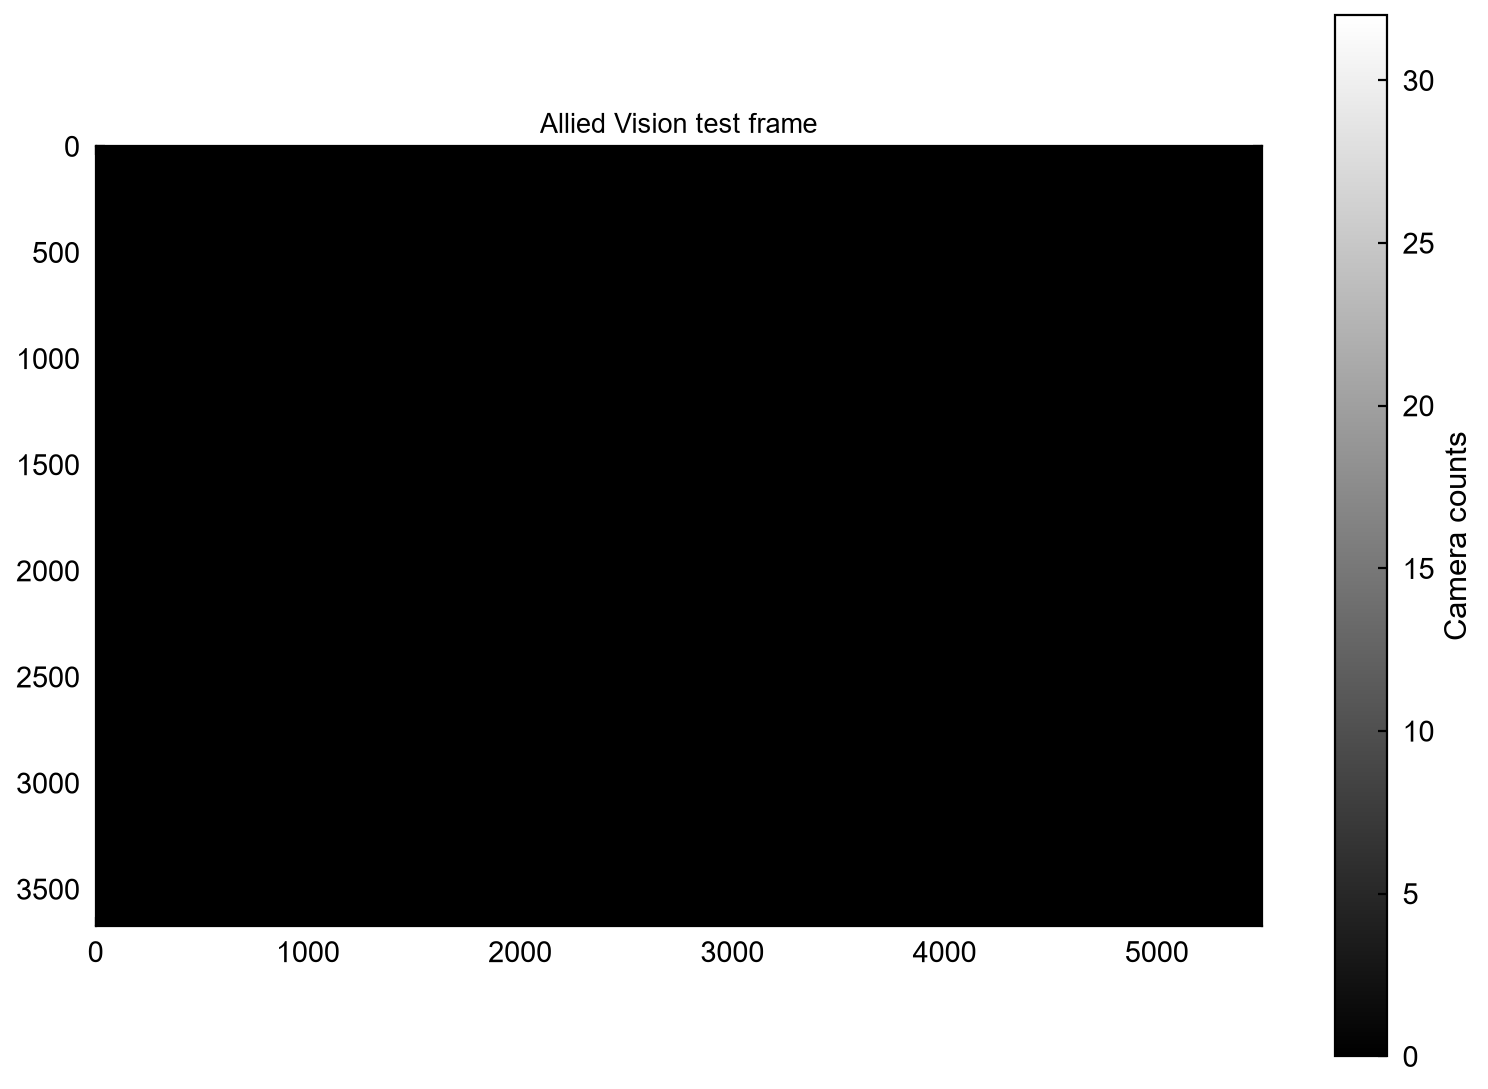

In [ ]:
plt.figure(figsize=(10, 7))

plt.imshow(
    img,
    cmap="gray",
    origin="upper"
)

plt.colorbar(label="Camera counts")
plt.title("Allied Vision test frame")

plt.tight_layout()
plt.show()

In [ ]:
img = cam.get_image()

print("Min  :", img.min())
print("Max  :", img.max())
print("Mean :", img.mean())

# Number of saturated pixels
n_sat = np.sum(img >= 255)
print("Saturated pixels:", n_sat)

# Brightest pixel
iy, ix = np.unravel_index(np.argmax(img), img.shape)
print(f"Brightest pixel: x={ix}, y={iy}, value={img[iy, ix]}")

Min  : 0
Max  : 32
Mean : 1.5856253547836732e-06
Saturated pixels: 0
Brightest pixel: x=3923, y=3671, value=32


## Calibration starts now

In [ ]:
from slmsuite.hardware.cameraslms import FourierSLM

fs = FourierSLM(cam, slm)

print(fs)

In [31]:
# Explicitly project the desired calibration grid
holo_cal = fs.fourier_grid_project(
    array_shape=9,
    array_pitch=16,
    array_center=(128, 0)   # confirmed +16-pixel carrier
)

  0%|          | 0/10 [00:00<?, ?it/s]

Max: 255
Saturated: 2851


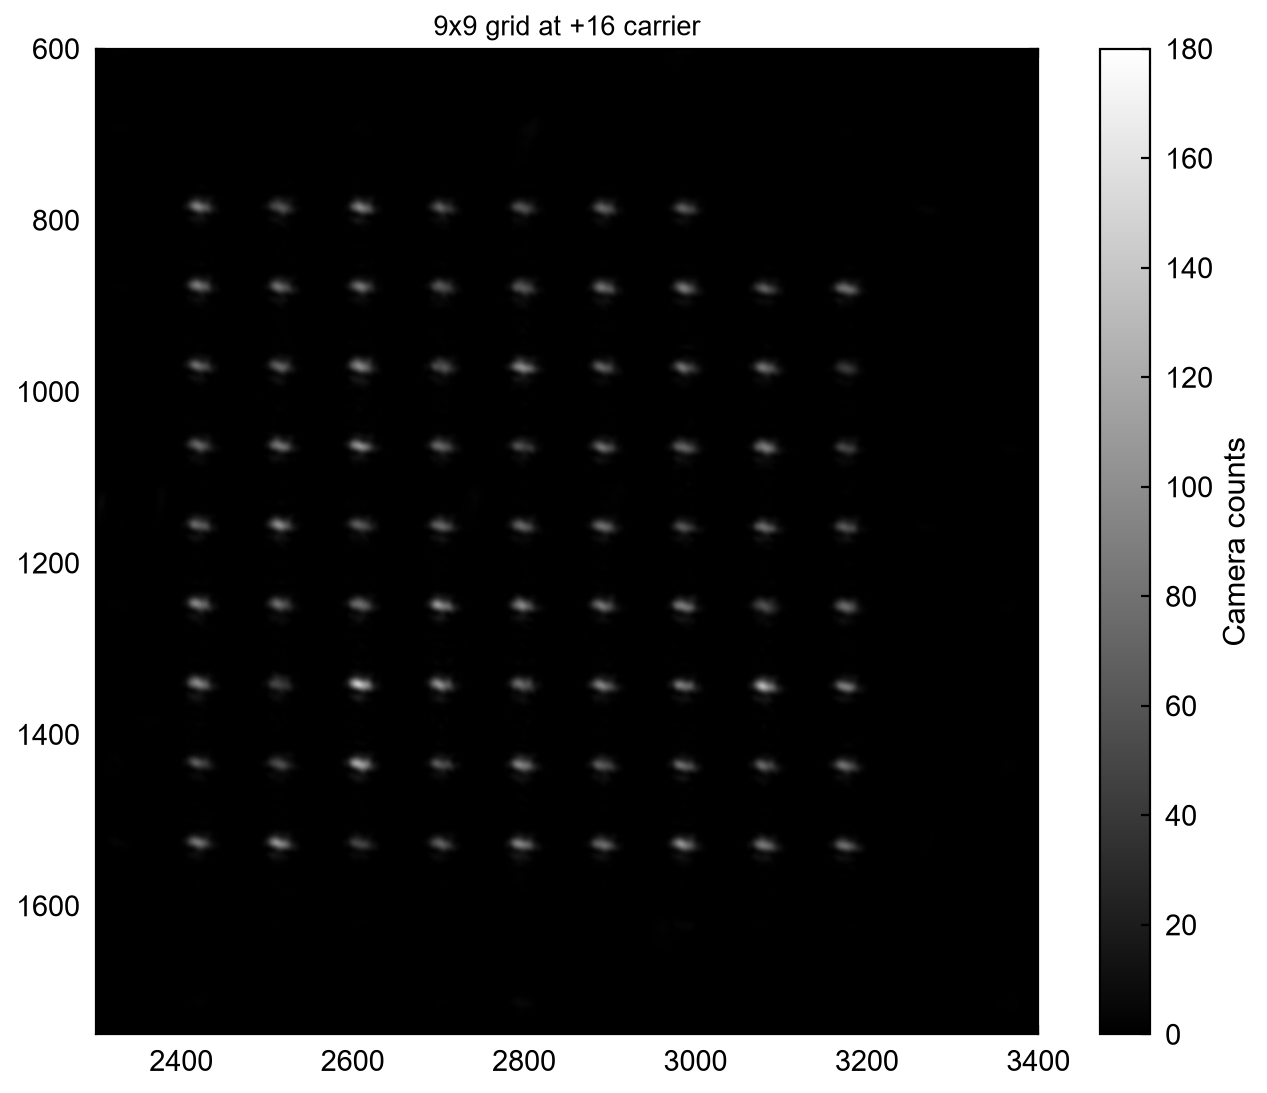

In [38]:
cam.set_exposure(0.0015)   # your current good starting point

img = cam.get_image()

print("Max:", img.max())
print("Saturated:", np.sum(img >= 255))

plt.figure(figsize=(10, 8))
plt.imshow(img, cmap="gray", vmin=0, vmax=180)

plt.xlim(2300, 3400)
plt.ylim(1750, 600)

plt.colorbar(label="Camera counts")
plt.title("9x9 grid at +16 carrier")
plt.show()

In [39]:
# Define the region containing the 9x9 calibration grid
x1, x2 = 2350, 3300
y1, y2 = 700, 1650

grid_roi = img[y1:y2, x1:x2]

print("=== FULL CAMERA ===")
print("Max:", img.max())
print("Saturated pixels:", np.sum(img >= 255))

print("\n=== 9x9 GRID ROI ===")
print("Max:", grid_roi.max())
print("Saturated pixels:", np.sum(grid_roi >= 255))

=== FULL CAMERA ===
Max: 255
Saturated pixels: 2851

=== 9x9 GRID ROI ===
Max: 145
Saturated pixels: 0


  0%|          | 0/10 [00:00<?, ?it/s]

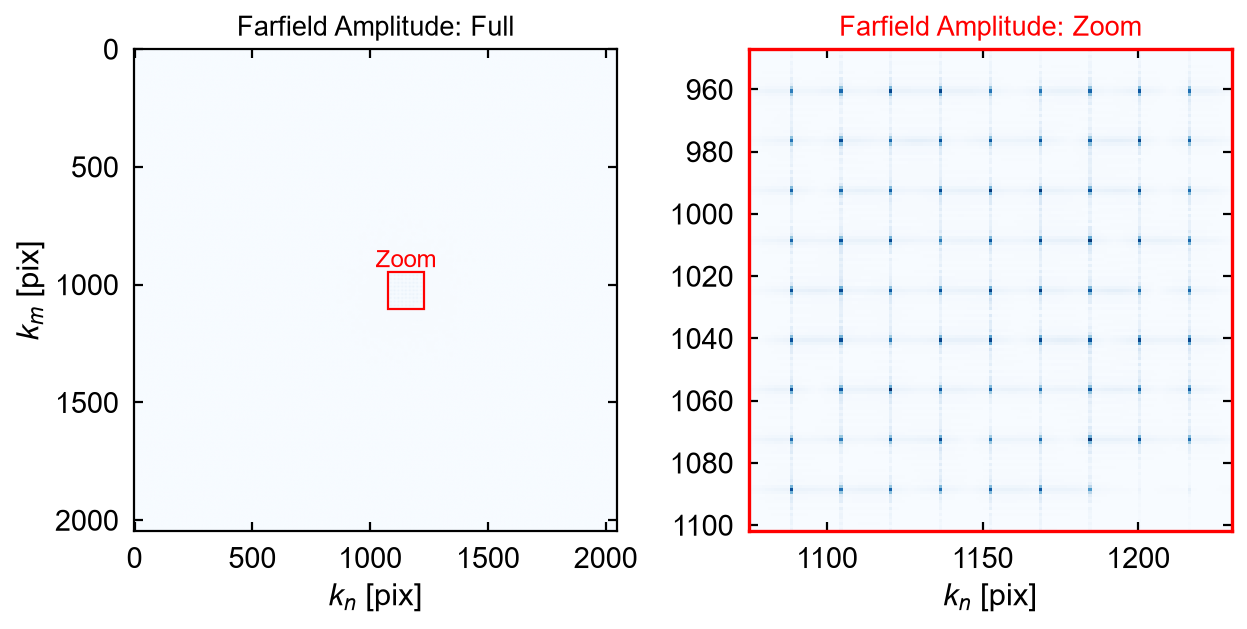

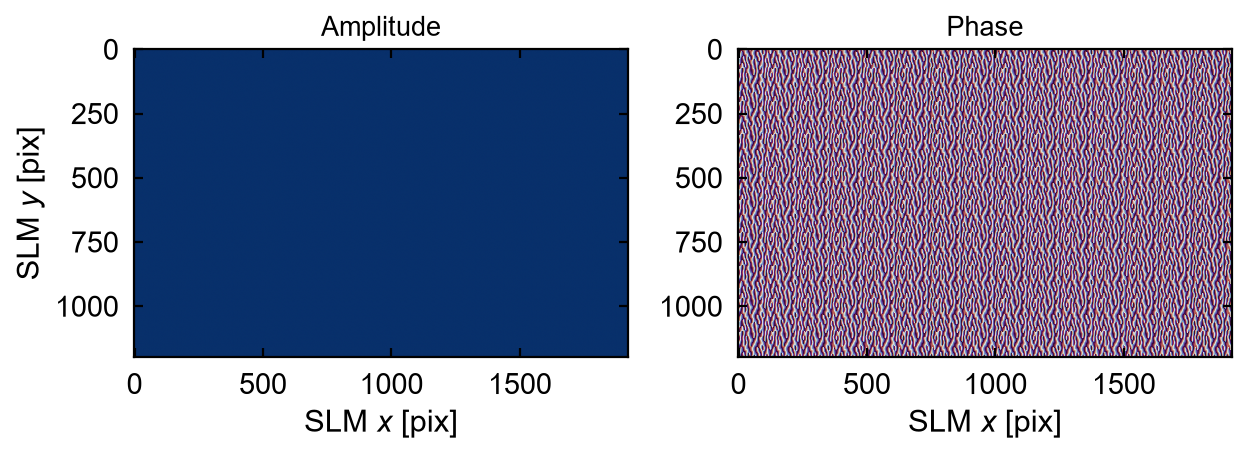

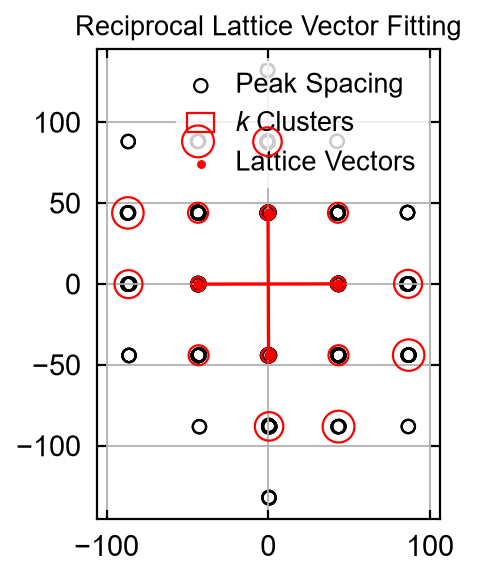

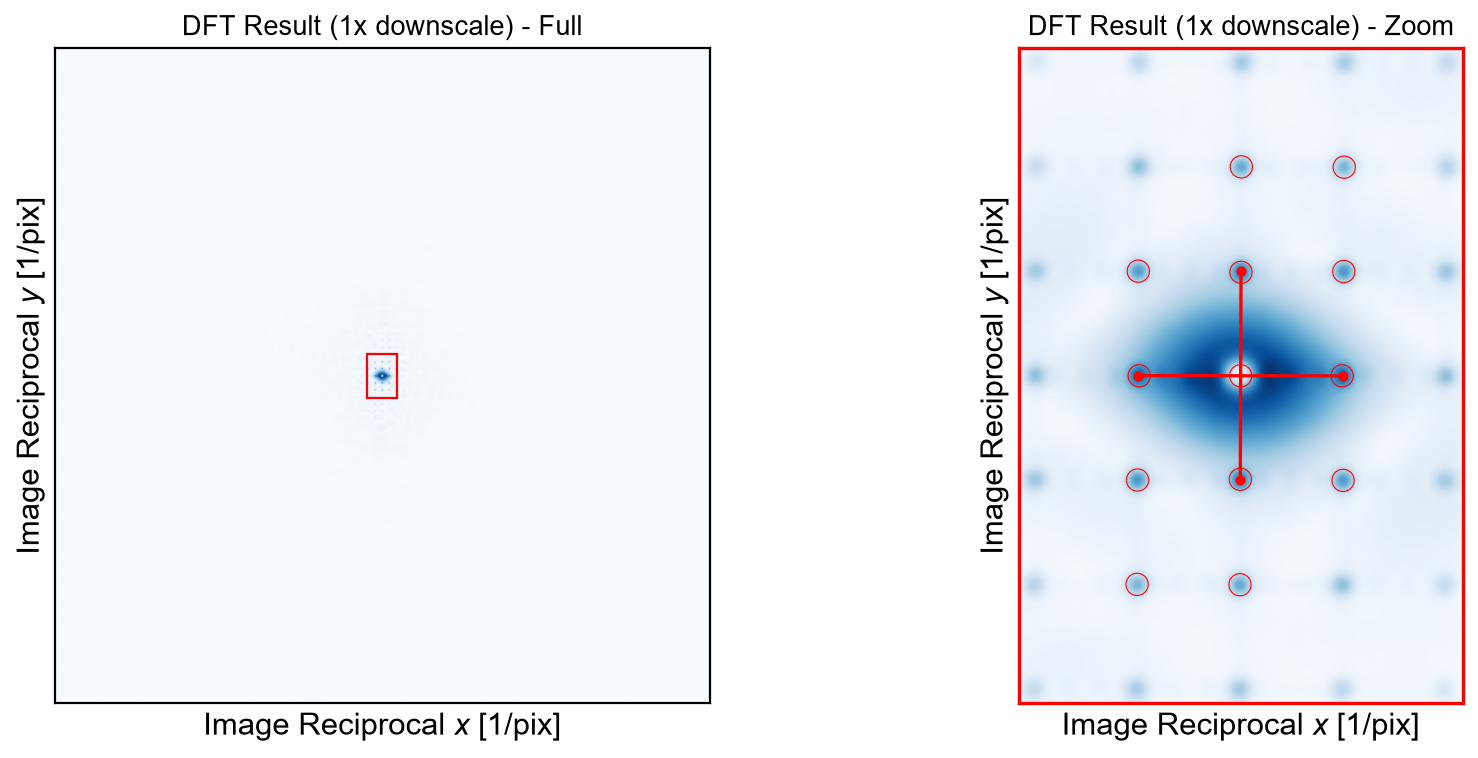

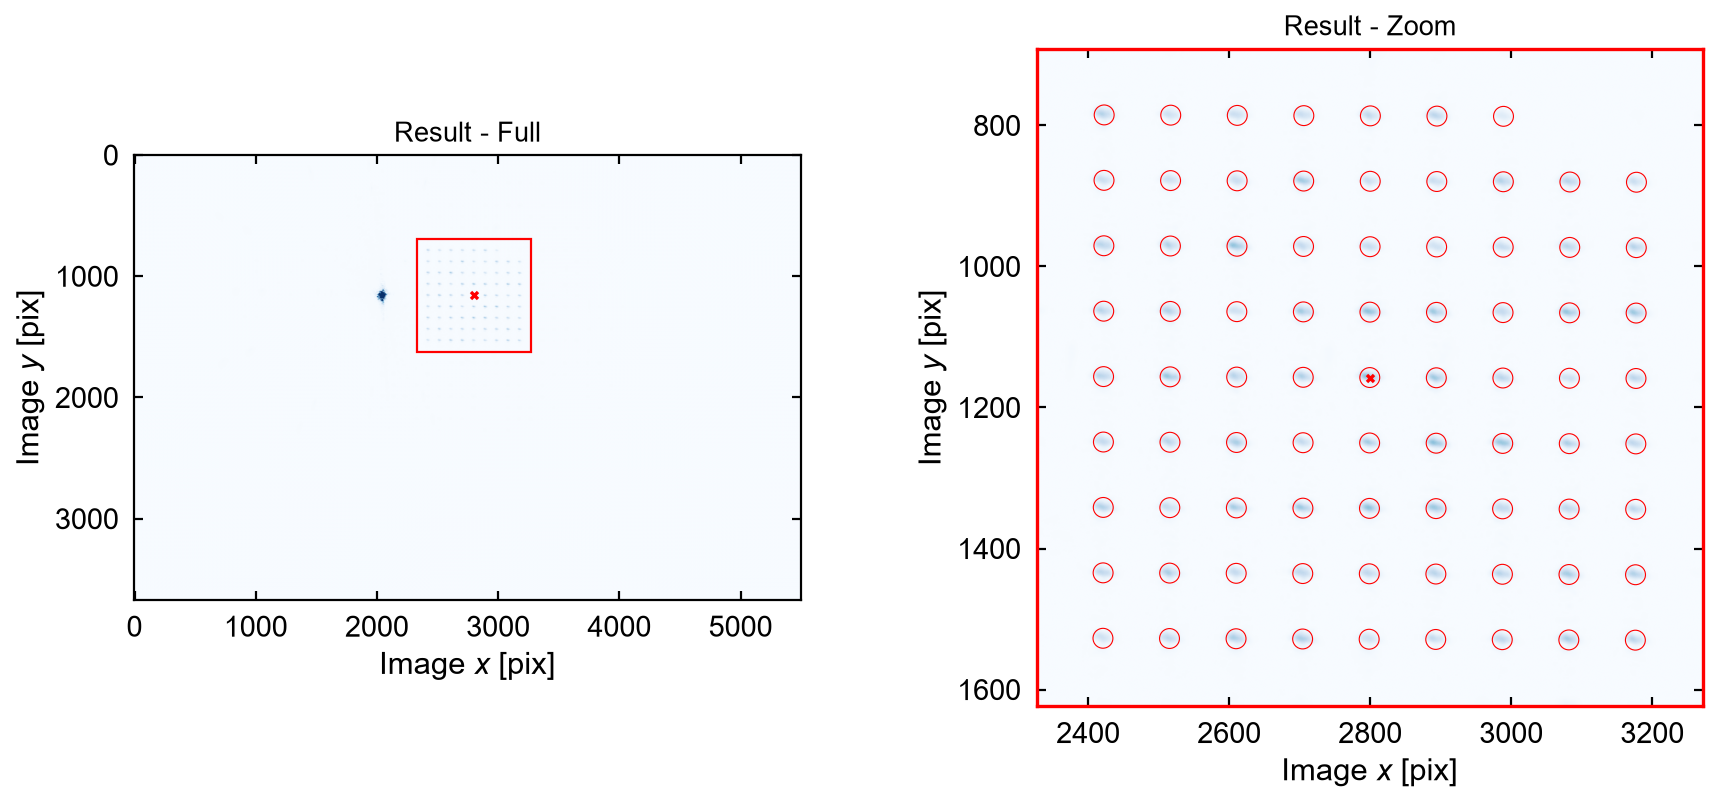

In [40]:
cal = fs.fourier_calibrate(
    array_shape=9,
    array_pitch=16,
    array_center=(128, 0),   # confirmed +16-pixel carrier
    autofocus=False,
    autoexposure=False,
    plot=2,
)

In [41]:
fourier = fs.calibrations["fourier"]

print("\n===== FOURIER CALIBRATION =====")

print("\nM =")
print(fourier["M"])

print("\nb =")
print(fourier["b"])

print("\na =")
print(fourier["a"])


===== FOURIER CALIBRATION =====

M =
[[ 127279.73025868     293.23159981]
 [    450.42127708 -125110.53609542]]

b =
[[2799.33492288]
 [1157.53158414]]

a =
[[5.93203125e-03]
 [5.63221908e-20]]


In [42]:
M = np.asarray(fourier["M"])

v1 = M[:, 0]
v2 = M[:, 1]

norm1 = np.linalg.norm(v1)
norm2 = np.linalg.norm(v2)

cos_angle = np.dot(v1, v2) / (norm1 * norm2)
cos_angle = np.clip(cos_angle, -1, 1)

angle_deg = np.degrees(np.arccos(cos_angle))

print("\n===== SANITY CHECK =====")
print("Column 1 norm :", norm1)
print("Column 2 norm :", norm2)
print("Angle [deg]   :", angle_deg)
print("det(M)        :", np.linalg.det(M))
print("Condition #   :", np.linalg.cond(M))


===== SANITY CHECK =====
Column 1 norm : 127280.52723825832
Column 2 norm : 125110.87973015805
Angle [deg]   : 90.06847068535309
det(M)        : -15924167364.495293
Condition #   : 1.0173840032182806


In [43]:
from pathlib import Path

print(Path.cwd())

c:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\After M change


In [44]:
save_path = fs.save_calibration(
    "fourier",
    path=".",
    name="YDFC_fourier_300-1000_plus16_pre-wavefront"
)

print("Saved to:")
print(save_path)

Saved to:
c:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\After M change\YDFC_fourier_300-1000_plus16_pre-wavefront_00000.h5


In [45]:
from pathlib import Path

p = Path(save_path)

print("Exists :", p.exists())
print("Name   :", p.name)
print("Folder :", p.parent)

Exists : True
Name   : YDFC_fourier_300-1000_plus16_pre-wavefront_00000.h5
Folder : c:\Users\admin\Desktop\Projects\SLM\SLM tests\Scripts\After M change
